# Autoregressive Processes of Order 2

Until now we have only looked at a simple equation where the value of a variable at time $t$ depends only on its value at time $t - 1$ (i.e., an autoregressive (AR) process of order 1). This is a very simple model that we can extend to include more lags, making it more flexible (we will discuss this in more details in next chapters). For now we are only interested to know if a process such as this forgets its initial condition and past shocks.

In the AR(2) we let the current value of the process depend on its value at time $t - 1$ and $t - 2$ and add some noise $e_t$. The equation of motion for this process is given by

$$
x_t = \phi_1 x_{t - 1} + \phi_2 x_{t - 2} + e_t
$$

In @fig-ar2-shock-difference you see a simulation of T=100 observation from a process with $\phi_1 = 0.2$ and $\phi_2 = 0.3$. Notice the (vertical) difference between the two paths at $t=10$. It is 5 units, because the (yellow) process has received an additional shock of 5 units at that time. You see that the two paths diverge after the shock but after a few periods they converge again. This means that the process forgets its past shocks.

:::{#ex-ar2-shock-difference}
## Shock Difference in AR(2) Process and Forgetfulness

Change the parameters $\phi_1$ and $\phi_2$ to different values and look if the paths coverge, diverge or remain parallel after $t=10$. Try out $\phi_1=0.5$ and $\phi_2=0.5$.

:::


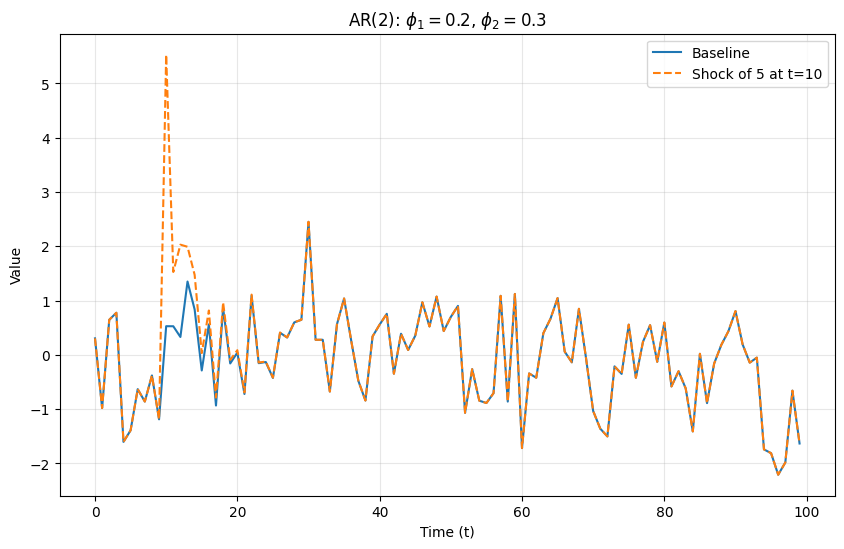

In [12]:
#| label: fig:ar2-shock-difference
#| fig-cap: "Two AR(2) paths with identical noise, except for a shock of 5 at t=2."

import numpy as np
import matplotlib.pyplot as plt

# Coefficients (change these to experiment)
phi_1 = 0.2
phi_2 = 0.3

# Simulation settings
T = 100
shock_size = 5
shock_time = 10
rng = np.random.default_rng(42)

# Same noise for both paths
noise = rng.normal(size=T)

# Path 1: baseline
x_base = np.zeros(T)
x_base[0] = noise[0]
x_base[1] = phi_1 * x_base[0] + noise[1]
for i in range(2, T):
    x_base[i] = phi_1 * x_base[i-1] + phi_2 * x_base[i-2] + noise[i]

# Path 2: identical noise, except a shock of 5 at t=2
noise_shocked = noise.copy()
noise_shocked[shock_time] += shock_size

x_shocked = np.zeros(T)
x_shocked[0] = noise_shocked[0]
x_shocked[1] = phi_1 * x_shocked[0] + noise_shocked[1]
for i in range(2, T):
    x_shocked[i] = phi_1 * x_shocked[i-1] + phi_2 * x_shocked[i-2] + noise_shocked[i]

# Plot both trajectories
plt.figure(figsize=(10, 6))
plt.plot(x_base, label='Baseline')
plt.plot(x_shocked, label=f'Shock of {shock_size} at t={shock_time}', linestyle='--')
plt.title(fr'AR(2): $\phi_1={phi_1}$, $\phi_2={phi_2}$')
plt.xlabel('Time (t)')
plt.ylabel('Value')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Forgetfulness Condition

The forgetfulness property of the AR(2) process depends on the values of $\phi_1$ and $\phi_2$. Past shocks dissipate over time if the roots of the characteristic equation of the AR process are less than 1 in absolute value. To derive the characteristic equation, we can use the lag operator $L$ to rewrite the AR(2) process as

$$
\begin{align*}
x_t & = \phi_1 L x_t + \phi_2 L^2 x_t + e_t \\
x_t = & (\phi_1 L + \phi_2 L^2) x_t + e_t \\
(1 - \phi_1 L - \phi_2 L^2) x_t = & e_t
\end{align*}
$$

We call the polynomial $1 - \phi_1 L - \phi_2 L^2$ the lag polynomial of the AR(2) process.
The characteristic equation is obtained by inverting the lag operator $L$ and setting the lag polynomial equal to zero:

$$
\begin{align*}
L^0 - \phi_1 L^1 - \phi_2 L^2 & = 0 \\
\lambda^{2 - 0} - \phi_1 \lambda^{2 - 1} - \phi_2 \lambda^{2 - 2} & = 0 \\
\lambda^2 - \phi_1 \lambda - \phi_2 & = 0
\end{align*}
$$

You obtain the characteristic equation by replacing the lag operator $L$ with $\lambda^{-1}$ and multiplying both sides by $\lambda^2$ (the highest power). The roots of the characteristic equation are given by.

:::{ex-ar2-characteristic-roots-stationary}
## Forgetfulness Condition for AR(2) Process

Look at

$$
x_t = 0.2 x_{t - 1} + 0.3 x_{t - 2} + e_t
$$

Its characteristic equation is:

$$
\lambda^2 - 0.2 \lambda - 0.3 = 0
$$

Also check the roots of the characteristic equation for the following AR(2) processes:

$$
\begin{align*}
x_t & = 0.5 x_{t - 1} + 0.5 x_{t - 2} + e_t \\
x_t & = 1.2 x_{t - 1} - 0.5 x_{t - 2} + e_t \\
x_t & = 0.5 x_{t - 1} + 0.5 x_{t - 2} + e_t
\end{align*}
$$

Go back to @fig-ar2-shock-difference and change the parameters $\phi_1$ and $\phi_2$ to the values above. Look if the paths converge, diverge or remain parallel after $t=10$.
:::

In [13]:
# Note how the list of coefficient is supplied:
# it starts with the coefficient of the highest order term (1 for lambda^2), 
# then the coefficient of lambda^1 (-phi_1), and finally the constant term (-phi_2).

np.roots([1, -0.2, -0.3])

array([ 0.65677644, -0.45677644])

## AR(2) as Vector AR(1) process

Until now we have checked the forgetfulness property of the AR(2) process by looking at the roots of the characteristic equation. However, it is not at all obvious where it comes from. Currently we only know how to study the forgetfulness property of the AR(1) process. So if we can somehow represent AR(2) as some sort of AR(1) process then we can lean on our previous knowledge. It turns out that we can do exactly that. Let's start by looking at the AR(2) process without the noise term and try to solve the equation just like we did for the AR(1) process.

:::{.ex-class}
$$
x_t = \phi_1 x_{t - 1} + \phi_2 x_{t - 2}
$$
:::

It becomes easier if we extend it to two dimensions by adding the equation $x_{t - 1} = x_{t - 1}$ to the system. This equation is trivially true but it allows us to write the AR(2) process as a system of two equations (this is a little bit like writing 0 as $a - a$ or $1 = a/a$in algebra).

:::{.ex-class}
$$
\begin{align*}
x_t & = \phi_1 x_{t - 1} + \phi_2 x_{t - 2}\\
x_{t - 1} & = x_{t - 1}\\
\end{align*}
$$
:::

At a first glance we have not done anything useful. But the usefulness of this approach becomes apparent if we write the two equations above in matrix form.

$$
\underbrace{\begin{pmatrix}
x_t \\
x_{t - 1}
\end{pmatrix}}_{z_t}
=
\underbrace{\begin{pmatrix}

\phi_1 & \phi_2 \\
1 & 0
\end{pmatrix}
}_{A}
\underbrace{\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}}_{z_{t - 1}}
$$

Note that we have not done anything special, we have just rewritten the same equation in a different form. However, this new form is very convenient because we can use simple substitution to represent $z_t$ as a function of $t$ and an initial condition $z_0$.

$$
\begin{align*}
z_t & = A z_{t - 1} \\
& = A (A z_{t - 2}) \\
& = A (A (A z_{t - 3})) \\
& = A^3 z_{t - 3} \\
& = A^t z_0
\end{align*}
$$

This looks just like the ordinary AR(1) process where we obtained the solution (again by substitution) and it was:

$$
\begin{align*}
x_t & = \phi x_{t - 1} \\
& = \phi (\phi x_{t - 2}) \\
& = \phi (\phi (\phi x_{t - 3})) \\
& = \phi^3 x_{t - 3} \\
& = \phi^t x_0
\end{align*}
$$

Both forms look very similar to each other. The AR(1) process was forgetful if $|\phi| < 1$ so that $\phi^t$ becomes small as time goes by ($t$ becomes large). Now we need to find out what is the condition for $A^t$ to become small as $t$ becomes large.

It turns out that the condition for $A^t$ to become small is the solutions of the characteristic equation of $A$ (the eigenvalues of $A$) are less than 1 in absolute value and that this is the exact same equation as we examined before.

## Where Does the Characteristic Equation Come From?

[What does does it mean to multiply a vector by a matrix?](https://www.desmos.com/calculator/ljm5qdlxav)


To cut a long story very short, it turns out that we can decompose the matrix $A$ into a product of three matrices:

$$
A = ELE^{-1}
$$

where $L$ is a diagonal matrix and $E^{-1}$ is the inverse of $E$. The inverse matrix is a matrix that when multiplied by the original matrix gives the identity matrix (a matrix with 1s on the diagonal and 0s elsewhere, in matrix multiplication it acts as the number 1 in ordinary multiplication).

$$
E^{-1} E = I = \begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}
$$

$$
IA = A = \begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}
\begin{pmatrix}
a & b \\
c & d
\end{pmatrix}
=
\begin{pmatrix}
a & b \\
c & d
\end{pmatrix}
$$

Now let's substitute the decomposition of $A$ into $A^t$:

$$
\begin{align*}
A^2 = & A A = (ELE^{-1})(ELE^{-1})= EL^2 E^{-1} \\
A^3 = & A A A = (ELE^{-1})(ELE^{-1})(ELE^{-1})= EL^3 E^{-1} \\
A^t = & A A ... A = (ELE^{-1})(ELE^{-1})...(ELE^{-1})= EL^t E^{-1}
\end{align*}
$$


Now, $L$ is a diagonal matrix, meaning that all of its non-diagonal elements are zero.

$$
L = \begin{pmatrix}
\lambda_1 & 0 \\
0 & \lambda_2
\end{pmatrix}
$$

One nice thing about diagonal matrices is that they are very easy to raise to a power. You just raise each of the diagonal elements to that power, check it out:

$$
\begin{align*}
L^2 = & L L = \begin{pmatrix}
\lambda_1 & 0 \\
0 & \lambda_2
\end{pmatrix}
\begin{pmatrix}
\lambda_1 & 0 \\
0 & \lambda_2
\end{pmatrix}
= \begin{pmatrix}
\lambda_1^2 & 0 \\
0 & \lambda_2^2
\end{pmatrix}
\end{align*}
$$

You can continue this until you arrive at $L^t$:

$$
L^t = \begin{pmatrix}
\lambda_1^t & 0 \\
0 & \lambda_2^t
\end{pmatrix}
$$

So if the diagonal entries $\lambda_1$ and $\lambda_2$ are less than 1 in absolute value, then $L^t$ will become small as $t$ becomes large.

## Where Do the Lambdas Come From?

Now, how to derive the diagonal matrix $L$? We will need to look at how the decomposition

$$
A = ELE^{-1}
$$

is derived in the first place.

[What are eigenvalues and eigenvectors?](https://www.desmos.com/calculator/vewpvnxrvj)

In general, multiplying a matrix (different from the zero-matrix) and a vector results in a new vector that is rotated (points in a different direction) and scaled (its length is changed: it is either stretched or compressed).

It turns out that for square matrices exist special vectors that when multiplied by the matrix are not rotated, but only scaled. These special vectors are called eigenvectors and the scaling factor is called the eigenvalue. Take one of the eigenvectors of $A$ and call it $v_1$. The whole matrix acting as a scaler (think of a simple real number) on the vector $v_1$ means that we can write the following equation:

$$
A v = \lambda v
$$

we can rearrange this equation to get

$$
(A - \lambda I) v = 0
$$

This means, however that the matrix $A - \lambda I$ is somehow special, because it takes a vector and sends it to the zero vector. Normally, this is what the zero matrix does, but this is not the zero matrix. Matrices with a property like this are called singular matrices and they have a special property: their determinant is zero. So we can write

$$
\text{det}(A - \lambda I) = 0
$$

Substitute with our matrix $A$ and the identity matrix $I$:

$$
\text{det}\left(\begin{pmatrix}
\phi_1 & \phi_2 \\
1 & 0
\end{pmatrix} - \lambda \begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}\right) = 0
$$

rearrange the terms and calculate the determinant:

$$
\text{det}\left(\begin{pmatrix}
\phi_1 - \lambda & \phi_2 \\
1 & -\lambda
\end{pmatrix}\right) = 0
$$


$$
(\phi_1 - \lambda)(-\lambda) - \phi_2 = 0
$$

Rearrange to obtain the characteristic equation:

$$
\lambda^2 - \phi_1 \lambda - \phi_2 = 0
$$